# Yammer Engagement Drop — Full Analysis Walkthrough

This notebook walks through the full investigation of a sustained engagement
drop on Yammer starting the week of **2014-08-04**, step by step: from
initial validation through to the root-cause hypothesis that best explains it.

Each section's SQL query is shown as reference (these were run against
`tutorial.yammer_events` / `tutorial.yammer_emails` / `tutorial.yammer_users` databases
in Mode. Queries are included here for completeness but don't execute from this
notebook). The Pandas cells below each one re-run the actual analysis against
the exported CSVs in the `../data/` directory.

**Companion files:** see `../README.md` for the headline summary, and
`../scripts/` for this same analysis as standalone Python files.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CORE_EVENTS = ["home_page", "login", "like_message", "send_message", "view_inbox"]
DIP_START = pd.Timestamp("2014-08-04")
BASELINE_WEEKS = pd.to_datetime(["2014-06-30","2014-07-07","2014-07-14","2014-07-21","2014-07-28"])
DIP_WEEKS = pd.to_datetime(["2014-08-04","2014-08-11","2014-08-18","2014-08-25"])
CORE_COLORS = dict(zip(CORE_EVENTS, plt.cm.tab10.colors))

def mark_dip(ax, label=True):
    # Shade the four dip weeks (08-04 to 08-25). Each weekly point is plotted
    # at its Monday start date, so pad by half a week on each side.
    kwargs = {"label": "Dip weeks (08-04 – 08-25)"} if label else {}
    ax.axvspan(DIP_WEEKS[0] - pd.Timedelta(days=3.5),
               DIP_WEEKS[-1] + pd.Timedelta(days=3.5),
               color="red", alpha=0.08, **kwargs)

### Which events are "core"?

The SQL export from Step 1 contains **17 engagement events**. I defined **core events** as
the five general-usage actions — `home_page`, `login`, `like_message`,
`send_message`, `view_inbox` — for two reasons:

1. They are the **five highest-volume events** (about 2,000–6,000 per week
   before the dip).
2. The other 12 events are all **search types**:
   `search_autocomplete`, `search_run`, and ten `search_click_result_N`.

The ten `search_click_result_N` have a low amount of events (about 35–100 per week) and
are noisy, so their percent changes mostly
reflect small-number noise. `search_autocomplete` and `search_run` are larger,
but they were not included as core events as
`search_autocomplete` had recovered from its dip by 08-25 and `search_run`
was noisy (~10%). `search_autocomplete` is treated as non-core due to
its week-to-week noise being as low as the core events' noise.

## Step 1 — Load & validate event data

**SQL (raw export for yammer_weekly_engagement.csv):**
```sql
-- sort events into weeks, get event counts, event types, and number of distinct users
SELECT
  DATE_TRUNC('week', occurred_at) AS week,
  event_name,
  COUNT(*) AS events,
  COUNT(DISTINCT user_id) AS distinct_users
FROM tutorial.yammer_events
WHERE event_type = 'engagement'
GROUP BY 1, 2
ORDER BY 2, 1
```


In [3]:
df = pd.read_csv("../data/yammer_weekly_engagement.csv", parse_dates=["week"])
df = df.sort_values(["event_name", "week"]).reset_index(drop=True)
df["prev_events"] = df.groupby("event_name")["events"].shift(1)
df["percent_change"] = (df["events"] - df["prev_events"]) / df["prev_events"] * 100
print(df.shape)
df.head() # preview the data

(306, 6)


,week,event_name,events,distinct_users,prev_events,percent_change
0,2014-04-28,home_page,2546,646,NaN,NaN
1,2014-05-05,home_page,5113,972,2546.0,100.824823
2,2014-05-12,home_page,5032,1015,5113.0,-1.584197
3,2014-05-19,home_page,5217,1056,5032.0,3.676471
4,2014-05-26,home_page,4978,1034,5217.0,-4.581177


**Validation note:** recreating `percent_change` in Pandas (float division)
vs. the original SQL output (`ROUND(100*(events-prev_events)/NULLIF(prev_events,0),1)`)
showed the SQL had truncated toward zero instead of rounding — for example,
`home_page` on 2014-08-04 was given as `-13` when the true value is `-13.68`.
Likely caused by integer division before `ROUND()` got decimal values. The Pandas-derived values
here are more accurate.

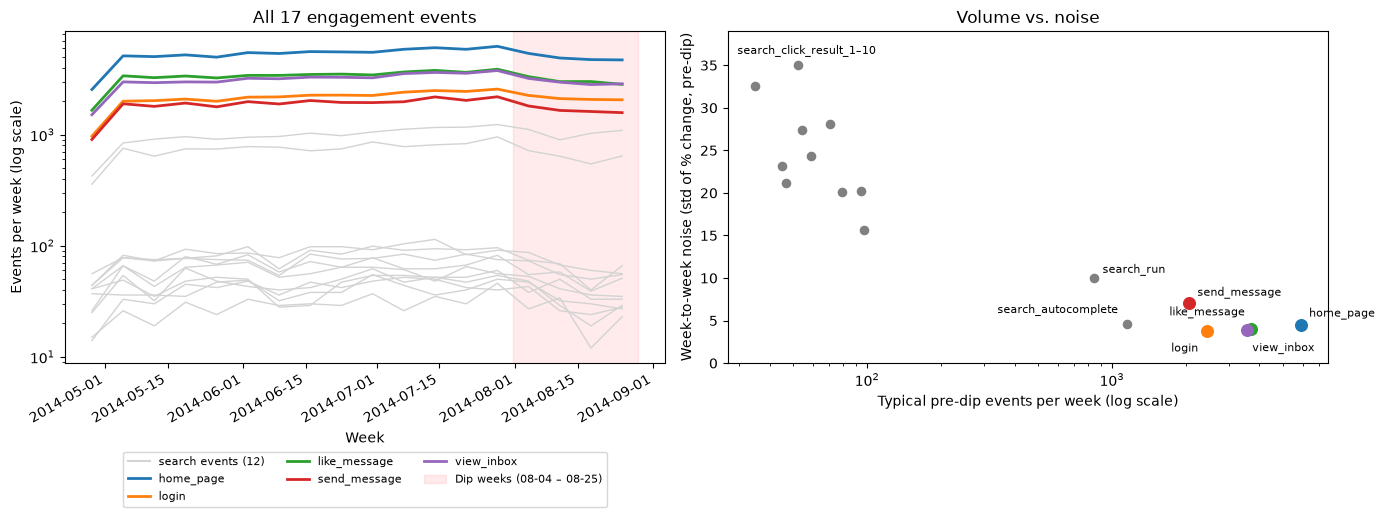

,baseline_avg_weekly,weekly_noise_std_pct,core
event_name,,,
home_page,5901.0,4.5,True
like_message,3680.0,4.0,True
view_inbox,3549.0,3.9,True
login,2433.0,3.8,True
send_message,2064.0,7.1,True
search_autocomplete,1146.0,4.6,False
search_run,846.0,10.0,False
search_click_result_2,97.0,15.6,False
search_click_result_1,94.0,20.2,False


In [4]:
# show all events (including non-core)
non_core = [e for e in df["event_name"].unique() if e not in CORE_EVENTS]

# Typical pre-dip volume, and week-to-week noise (std of % change) before the dip.
# Noise window starts 05-12 to skip the partial-first-week artifact.
pre_volume = df[df["week"].isin(BASELINE_WEEKS)].groupby("event_name")["events"].mean()
noise_rows = (df["week"] >= "2014-05-12") & (df["week"] <= "2014-07-28")
pre_noise = df[noise_rows].groupby("event_name")["percent_change"].std()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: every event over time (log scale), core events highlighted
for event in non_core:
    sub = df[df["event_name"] == event]
    ax1.plot(sub["week"], sub["events"], color="lightgray", linewidth=1)
ax1.plot([], [], color="lightgray", label=f"search events ({len(non_core)})")
for event in CORE_EVENTS:
    sub = df[df["event_name"] == event]
    ax1.plot(sub["week"], sub["events"], color=CORE_COLORS[event], linewidth=2, label=event)
mark_dip(ax1)
ax1.set_yscale("log")
ax1.set_xlabel("Week"); ax1.set_ylabel("Events per week (log scale)")
ax1.set_title("All 17 engagement events")
ax1.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3)
for label in ax1.get_xticklabels():
    label.set_rotation(30); label.set_ha("right")

# Right: volume vs. noise
LABEL_OFFSETS = {
    "home_page": (6, 6, "left"), "like_message": (-4, 10, "right"),
    "view_inbox": (4, -15, "left"), "login": (-6, -15, "right"),
    "send_message": (6, 5, "left"), "search_autocomplete": (-6, 8, "right"),
    "search_run": (6, 4, "left"),
}
for event in pre_volume.index:
    is_core = event in CORE_EVENTS
    ax2.scatter(pre_volume[event], pre_noise[event], s=70 if is_core else 35,
                color=CORE_COLORS[event] if is_core else "gray", zorder=3)
    if event in LABEL_OFFSETS:
        dx, dy, ha = LABEL_OFFSETS[event]
        ax2.annotate(event, (pre_volume[event], pre_noise[event]),
                     textcoords="offset points", xytext=(dx, dy), ha=ha, fontsize=8)
clicks = [e for e in pre_volume.index if e.startswith("search_click_result")]
ax2.annotate("search_click_result_1–10", (pre_volume[clicks].median(), pre_noise[clicks].max()),
             textcoords="offset points", xytext=(0, 8), fontsize=8, ha="center")
ax2.set_xscale("log")
ax2.set_xlabel("Typical pre-dip events per week (log scale)")
ax2.set_ylabel("Week-to-week noise (std of % change, pre-dip)")
ax2.set_ylim(0, 39)
ax2.set_title("Volume vs. noise")
fig.tight_layout()
plt.show()

pd.DataFrame({
    "baseline_avg_weekly": pre_volume.round(0),
    "weekly_noise_std_pct": pre_noise.round(1),
    "core": [e in CORE_EVENTS for e in pre_volume.index],
}).sort_values("baseline_avg_weekly", ascending=False)

The five core events are the high-volume group, and all are consistent enough
(<10% week-to-week noise) for percent changes to be meaningful. For the below analysis,
plots focus on core event types only.

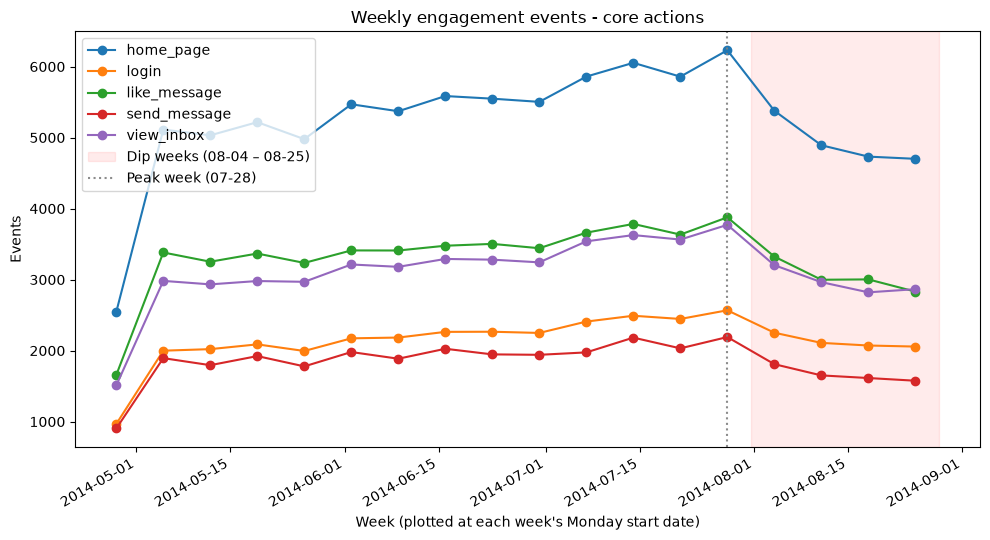

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for event in CORE_EVENTS:
    subset = df[df["event_name"] == event]
    ax.plot(subset["week"], subset["events"], marker="o", label=event, color=CORE_COLORS[event])
mark_dip(ax)
ax.axvline(pd.Timestamp("2014-07-28"), color="gray", linestyle=":", alpha=0.9,
           label="Peak week (07-28)")
ax.set_xlabel("Week (plotted at each week's Monday start date)"); ax.set_ylabel("Events")
ax.set_title("Weekly engagement events - core actions")
ax.legend()
fig.autofmt_xdate(); fig.tight_layout()
plt.show()
fig.savefig("../figures/core_events_trend.png", dpi=150, bbox_inches="tight")

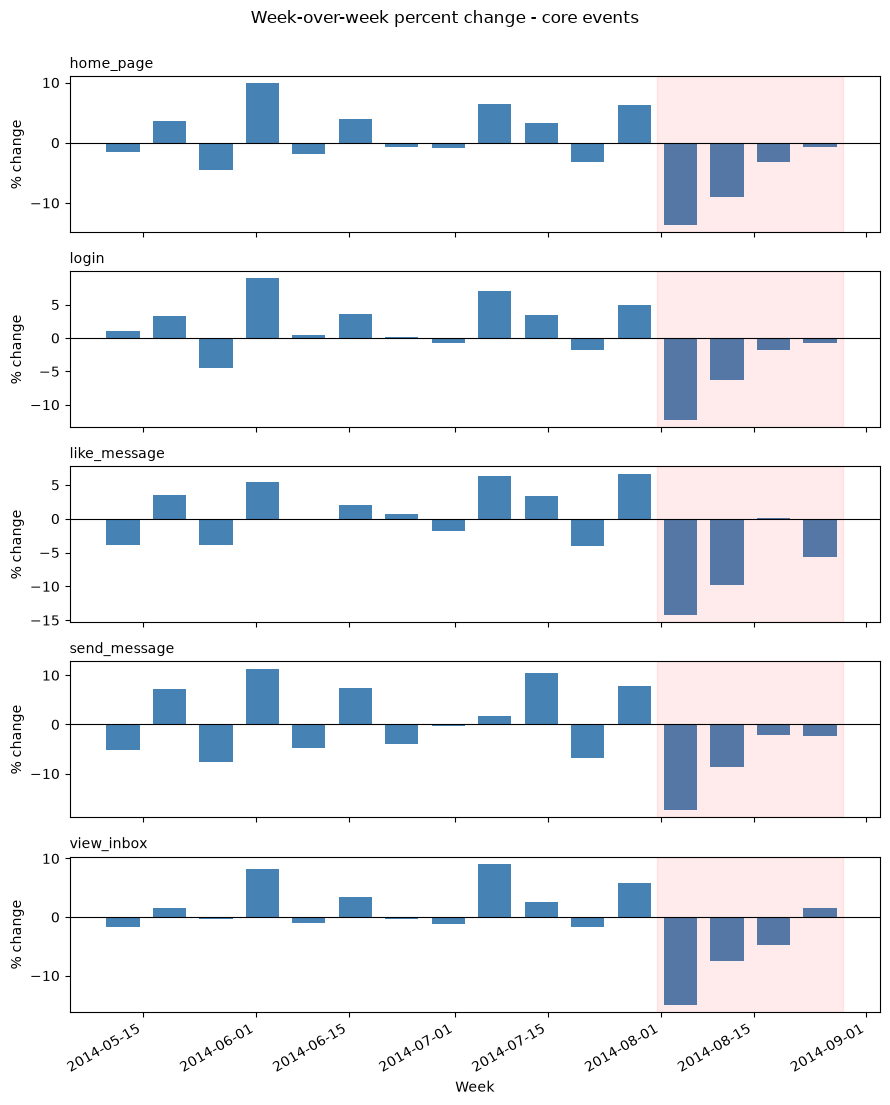

In [6]:
weeks_sorted = sorted(df["week"].unique())
plot_start = weeks_sorted[2]  # skip first 2 weeks: no prior week, then a partial-week artifact

fig, axes = plt.subplots(len(CORE_EVENTS), 1, figsize=(9, 11), sharex=True)
for ax, event in zip(axes, CORE_EVENTS):
    subset = df[(df["event_name"] == event) & (df["week"] >= plot_start)]
    ax.bar(subset["week"], subset["percent_change"], width=5, color="steelblue")
    ax.axhline(0, color="black", linewidth=0.8)
    mark_dip(ax)
    ax.set_title(event, loc="left", fontsize=10)
    ax.set_ylabel("% change")
axes[-1].set_xlabel("Week")
fig.suptitle("Week-over-week percent change - core events", y=1.0)
fig.autofmt_xdate(); fig.tight_layout()
plt.show()
fig.savefig("../figures/core_events_pct_change.png", dpi=150, bbox_inches="tight")

**Note: Why `08-04` is the first dip week (and not `07-28`).** Each point on the above plot represents a
week, plotted at its Monday start date (`DATE_TRUNC('week', ...)`), so the
point labeled 07-28 is the week of 07-28 – 08-03. That week is the **peak** of the
series for all five core events. The downward slope between the 07-28 and 08-04 markers 
is the drop *into* the 08-04 week, the first week with lower volume. That is why the 
shaded dip region starts at 08-04 and why week-over-week change is first negative there.

Note that weekly buckets can't show the exact *day* the decline began. A SQL query with day
  would increase the precision.

**Step 1 Takeaway:** every core event peaks the week of 07-28, then drops sharply
starting 08-04 and stays depressed through 08-25 without recovering, 
demonstrating a sustained decline.

## Step 2 — Fewer users, or less per-user activity?

**SQL:** uses same query as Step 1 (`distinct_users` is already in that query).

**Pandas:**
```python
df["events_per_user"] = df["events"] / df["distinct_users"]
# + groupby("event_name").shift(1) to get week-over-week pct_change
# for events, distinct_users, and events_per_user
```

The per-event raw `distinct_users` data isn't re-loaded here (see ``02_events_per_user.py`` 
for the script). The dip-week percent-change results from that script are shown below.

In [7]:
dip_summary = pd.DataFrame({
    "home_page":    {"events": [-13.7,-9.0,-3.3,-0.7], "distinct_users": [-12.8,-5.0,-0.9,-0.1], "events_per_user": [-1.0,-4.3,-2.4,-0.6]},
    "like_message": {"events": [-14.3,-9.8,0.2,-5.7],  "distinct_users": [-9.0,-8.2,0.6,-4.8],   "events_per_user": [-5.8,-1.7,-0.5,-0.9]},
    "login":        {"events": [-12.3,-6.3,-1.8,-0.7], "distinct_users": [-12.2,-4.0,-1.0,-0.7], "events_per_user": [-0.1,-2.4,-0.8,0.0]},
    "send_message": {"events": [-17.4,-8.7,-2.2,-2.4], "distinct_users": [-11.4,-8.0,1.1,-0.7],  "events_per_user": [-6.8,-0.7,-3.3,-1.7]},
    "view_inbox":   {"events": [-15.1,-7.5,-4.8,1.6],  "distinct_users": [-11.3,-5.9,0.0,-1.5],  "events_per_user": [-4.3,-1.6,-4.8,3.1]},
}).T

avg_pct = pd.DataFrame({f"pct_change_{c}": dip_summary[c].apply(np.mean) for c in dip_summary.columns})
print("Average week-over-week percent change across the 4 dip weeks, per event:\n")
print(avg_pct.round(1).to_string())

Average week-over-week percent change across the 4 dip weeks, per event:

              pct_change_events  pct_change_distinct_users  pct_change_events_per_user
home_page                  -6.7                       -4.7                        -2.1
like_message               -7.4                       -5.4                        -2.2
login                      -5.3                       -4.5                        -0.8
send_message               -7.7                       -4.7                        -3.1
view_inbox                 -6.4                       -4.7                        -1.9


**Takeaway:** Since the percent change from distinct users is more negative than the percent change per user, we can conclude that most of the dip comes from fewer distinct users engaging, with the rest of the dip due to those users having less activity.

## Step 3 — Exact decomposition: users vs. per-user activity

Let's examine the distinction from Step 2 in a plot.

Percent changes are only *approximately* additive
(`users% + per_user% ≈ total%`), so a share calculation won't sum to
exactly 100%. Since `events = distinct_users × events_per_user` by
definition, growth **factors** multiply exactly and therefore their **logs add
exactly**:

```
log(events_growth) = log(users_growth) + log(per_user_growth)
```

This holds per-week and stays exact after averaging, giving an exact 100%
split instead of an approximate one.

In [8]:
def log_growth_shares(weekly_pct_dict):
    rows = {}
    for event, cols in weekly_pct_dict.items():
        lg = {c: np.mean([np.log(1 + v/100) for v in vals]) for c, vals in cols.items()}
        rows[event] = {
            "pct_change_events": np.mean(cols["events"]),
            "share_users": lg["distinct_users"] / lg["events"] * 100,
            "share_per_user": lg["events_per_user"] / lg["events"] * 100,
        }
    return pd.DataFrame(rows).T

core_shares = log_growth_shares(dip_summary.to_dict(orient="index"))
core_shares = core_shares.sort_values("pct_change_events")
print(core_shares.round(1).to_string())

              pct_change_events  share_users  share_per_user
send_message               -7.7         61.0            39.0
like_message               -7.4         71.0            29.0
home_page                  -6.7         70.3            29.9
view_inbox                 -6.4         71.2            28.6
login                      -5.3         84.9            15.0


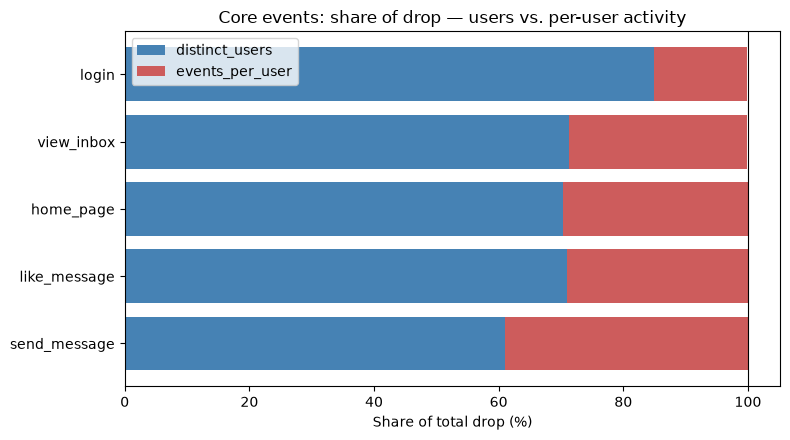

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y_pos = range(len(core_shares))
ax.barh(y_pos, core_shares["share_users"], color="steelblue", label="distinct_users")
ax.barh(y_pos, core_shares["share_per_user"], left=core_shares["share_users"], color="indianred", label="events_per_user")
ax.set_yticks(list(y_pos)); ax.set_yticklabels(core_shares.index)
ax.axvline(100, color="black", linewidth=0.8)
ax.set_xlabel("Share of total drop (%)")
ax.set_title("Core events: share of drop — users vs. per-user activity")
ax.legend(); fig.tight_layout()
plt.show()

**Takeaway:** fewer distinct users is the dominant driver for each core event
(61-85% of each event's drop), with an additional smaller, consistent secondary decline
in per-user activity. `login` dips mainly due to
"fewer users" while `send_message` has the most balanced split (61/39).

## Intermediate analysis: Hypothesis testing

Five candidate explanations for the drop, tested in order of how directly
testable they were against the available tables.

### Hypothesis: email notifications stopped sending, reducing site traffic

**SQL:**
```sql
SELECT
  DATE_TRUNC('week', occurred_at) AS week,
  action,
  COUNT(*) AS email_events
FROM tutorial.yammer_emails
GROUP BY 1, 2
ORDER BY 2, 1
```

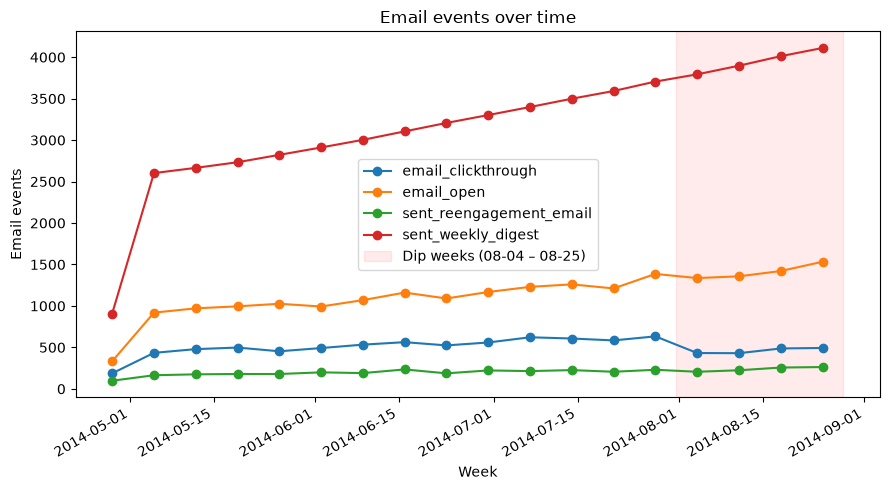

In [10]:
emails = pd.read_csv("../data/yammer_emails.csv", parse_dates=["week"])
fig, ax = plt.subplots(figsize=(9, 5))
for action in emails["action"].unique():
    sub = emails[emails["action"] == action]
    ax.plot(sub["week"], sub["email_events"], marker="o", label=action)
mark_dip(ax)
ax.set_xlabel("Week"); ax.set_ylabel("Email events"); ax.legend()
ax.set_title("Email events over time")
fig.autofmt_xdate(); fig.tight_layout()
plt.show()

**Verdict: email notifications not being sent -- ruled out.** `sent_weekly_digest` and
`sent_reengagement_email` volumes *increased* every week through the dip, so they wouldn't have been the cause of the drop.

**But a related signal is worth checking: did the clickthrough *rate*
change, independent of volume?** We can see from the plot that the email clickthrough events decrease during the dip period.

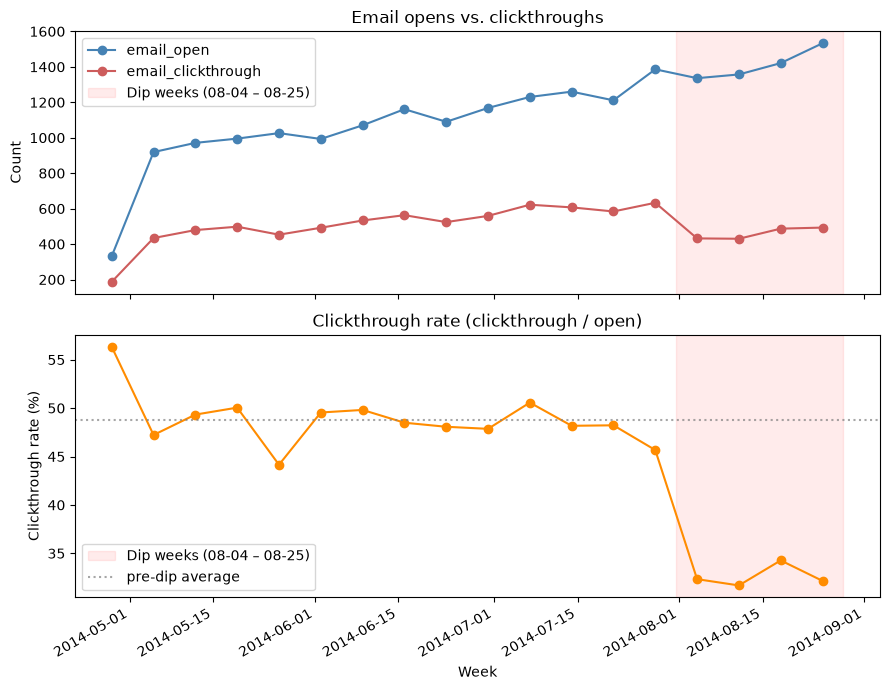

Baseline avg clickthrough rate: 48.1%
Dip avg clickthrough rate: 32.6%
Relative change: -32.2%


In [11]:
wide = emails.pivot(index="week", columns="action", values="email_events").reset_index()
wide["clickthrough_rate"] = wide["email_clickthrough"] / wide["email_open"] * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax1.plot(wide["week"], wide["email_open"], marker="o", label="email_open", color="steelblue")
ax1.plot(wide["week"], wide["email_clickthrough"], marker="o", label="email_clickthrough", color="indianred")
mark_dip(ax1)
ax1.set_ylabel("Count"); ax1.set_title("Email opens vs. clickthroughs"); ax1.legend()

pre_dip_avg = wide.loc[wide["week"] < DIP_START, "clickthrough_rate"].mean()
ax2.plot(wide["week"], wide["clickthrough_rate"], marker="o", color="darkorange")
mark_dip(ax2)
ax2.axhline(pre_dip_avg, color="gray", linestyle=":", alpha=0.7, label="pre-dip average")
ax2.set_ylabel("Clickthrough rate (%)"); ax2.set_xlabel("Week")
ax2.set_title("Clickthrough rate (clickthrough / open)"); ax2.legend()
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig("../figures/email_clickthrough_rate.png", dpi=150, bbox_inches="tight")
plt.show()

baseline_rate = wide[wide["week"].isin(BASELINE_WEEKS)]["clickthrough_rate"].mean()
dip_rate = wide[wide["week"].isin(DIP_WEEKS)]["clickthrough_rate"].mean()
print(f"Baseline avg clickthrough rate: {baseline_rate:.1f}%")
print(f"Dip avg clickthrough rate: {dip_rate:.1f}%")
print(f"Relative change: {(dip_rate-baseline_rate)/baseline_rate*100:.1f}%")

**Verdict: email clickthroughs decreasing is a real signal.** `email_open`
kept growing right through the dip (1336 → 1533), but the clickthrough
**rate** collapsed from a ~48% baseline to ~32.6% starting the exact same
week as the engagement drop — and, unlike raw engagement, it shows **no
recovery** at all through 08-25.

This indicates that emails were sent and opened, but a much smaller share clicked through. Clicks themselves
fell about 32% in the first dip week (633 → 432) while opens barely moved, so this isn't just opens rising.

The email table has no device or email-type breakdown, so the clickthrough issue can't be traced.
A broken landing experience (on mobile or elsewhere), a change to the emails'
links or layout, or a click-tracking problem would all produce this pattern.
It is consistent with the cohort x device conclusion below (a broad
disruption, mobile hit hardest) but doesn't distinguish between the
explanations.

### Hypothesis: holiday / regional concentration

A holiday or regional event/holiday would show up as a drop **concentrated in
particular countries or regions**. If every country fell by about the same
percentage, location isn't the explanation.

**SQL (weekly events by country):**
```sql
--group events by location
SELECT
  DATE_TRUNC('week', occurred_at) AS week,
  location,
  COUNT(*) AS events
FROM tutorial.yammer_events
WHERE event_type = 'engagement'
GROUP BY 1, 2
ORDER BY 2, 1
```

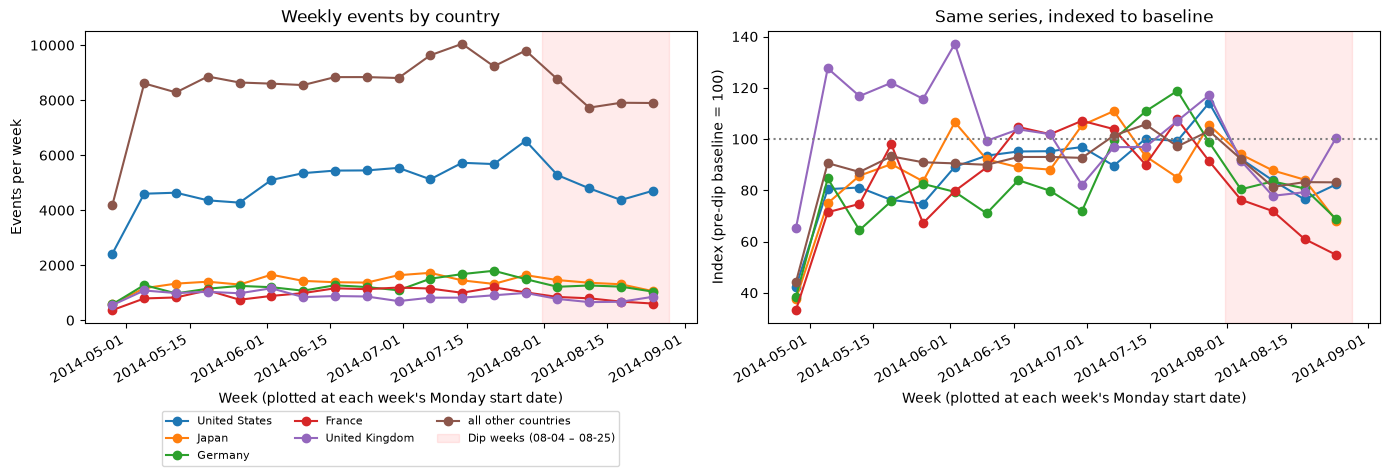

In [12]:
loc_weekly = pd.read_csv("../data/yammer_location_weekly.csv", parse_dates=["week"])
wide = loc_weekly.pivot(index="week", columns="location", values="events")

# Top 5 countries by pre-dip volume, plus everyone else combined
top5 = wide.loc[BASELINE_WEEKS].mean().sort_values(ascending=False).index[:5]
grouped = wide[top5].assign(**{"all other countries": wide.drop(columns=top5).sum(axis=1)})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for col in grouped.columns:
    ax1.plot(grouped.index, grouped[col], marker="o", label=col)
    indexed = grouped[col] / grouped.loc[BASELINE_WEEKS, col].mean() * 100
    ax2.plot(grouped.index, indexed, marker="o", label=col)
for ax in (ax1, ax2):
    mark_dip(ax, label=(ax is ax1))
    ax.set_xlabel("Week (plotted at each week's Monday start date)")
ax1.set_ylabel("Events per week"); ax1.set_title("Weekly events by country")
ax2.set_ylabel("Index (pre-dip baseline = 100)"); ax2.axhline(100, color="gray", linestyle=":")
ax2.set_title("Same series, indexed to baseline")
ax1.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3)
fig.autofmt_xdate(); fig.tight_layout()
plt.show()

In [13]:
b = wide.loc[BASELINE_WEEKS].mean(); d = wide.loc[DIP_WEEKS].mean()
country = pd.DataFrame({"baseline_wk": b, "dip_wk": d})
country["level_change_%"] = (d - b) / b * 100
country["share_of_volume_%"] = b / b.sum() * 100
country["share_of_loss_%"] = (b - d) / (b - d).sum() * 100
country = country.sort_values("baseline_wk", ascending=False).round(1)
print(country.head(10).to_string())

us = "United States"
rest_change = (d.drop(us).sum() - b.drop(us).sum()) / b.drop(us).sum() * 100
all_change = (d.sum() - b.sum()) / b.sum() * 100
print(f"US: {country.loc[us, 'level_change_%']:.1f}%  |  all other countries: {rest_change:.1f}%  |  all countries: {all_change:.1f}%")
print(f"Countries with a drop: {(country['level_change_%'] < 0).sum()} of {len(country)}")

                baseline_wk  dip_wk  level_change_%  share_of_volume_%  share_of_loss_%
location                                                                               
United States        5718.6  4788.2           -16.3               28.2             27.1
Japan                1554.4  1298.0           -16.5                7.7              7.5
Germany              1514.2  1186.0           -21.7                7.5              9.6
France               1110.0   732.5           -34.0                5.5             11.0
United Kingdom        848.0   740.2           -12.7                4.2              3.1
Italy                 779.4   607.5           -22.1                3.8              5.0
Brazil                671.6   541.0           -19.4                3.3              3.8
Russia                653.4   588.5            -9.9                3.2              1.9
India                 636.6   399.2           -37.3                3.1              6.9
Canada                540.4   34

In [14]:
# Regions are roughly grouped.
REGIONS = {
    "Europe": ["France", "Germany", "United Kingdom", "Italy", "Spain", "Netherlands", "Sweden",
               "Poland", "Switzerland", "Belgium", "Austria", "Denmark", "Norway", "Finland",
               "Ireland", "Portugal", "Greece", "Russia"],
    "Americas": ["United States", "Canada", "Brazil", "Mexico", "Argentina", "Chile",
                 "Colombia", "Venezuela"],
    "Asia-Pacific": ["Japan", "Korea", "India", "Indonesia", "Australia", "Taiwan", "Malaysia",
                     "Thailand", "Philippines", "Hong Kong", "Singapore"],
    "Middle East / Africa / other": ["Saudi Arabia", "Iran", "Iraq", "Israel", "United Arab Emirates",
                                     "Egypt", "Nigeria", "South Africa", "Pakistan", "Turkey"],
}
assert set(sum(REGIONS.values(), [])) == set(wide.columns), "some countries are not assigned to a region"

pd.DataFrame([
    {"region": name, "baseline_wk": b[members].sum(),
     "level_change_%": (d[members].sum() - b[members].sum()) / b[members].sum() * 100,
     "share_of_volume_%": b[members].sum() / b.sum() * 100}
    for name, members in REGIONS.items()
]).round(1)

,region,baseline_wk,level_change_%,share_of_volume_%
0,Europe,7001.6,-17.3,34.6
1,Americas,7897.4,-18.1,39.0
2,Asia-Pacific,4091.8,-18.7,20.2
3,Middle East / Africa / other,1259.4,-2.2,6.2


**Verdict: holiday/regional based drop ruled out.** The drop is not concentrated in any country or
region. The US fell 16.3%, similar to all other countries combined (-17.2%); 
it accounts for 27.1% of the events lost
versus 28.2% of baseline volume. All 15 of the largest
countries fell, indicating that the drop was not region-specific.

Countries do vary: France (-34%), India (-37%), and Canada (-36%) fell most
and account for more of the loss than their size suggests, while the UK
(-13%) and Russia (-10%) fell less. For
the US alone to explain the 17% aggregate drop with every other country
flat, it would have needed to fall about 61%, versus the observed 16.3% (`aggregate_drop ≈ share × country_drop`).

### Hypothesis: drop in new signups

**SQL:**
```sql
SELECT DATE_TRUNC('week', created_at) AS week, COUNT(*) AS signups
FROM tutorial.yammer_users
GROUP BY 1
ORDER BY 1
```

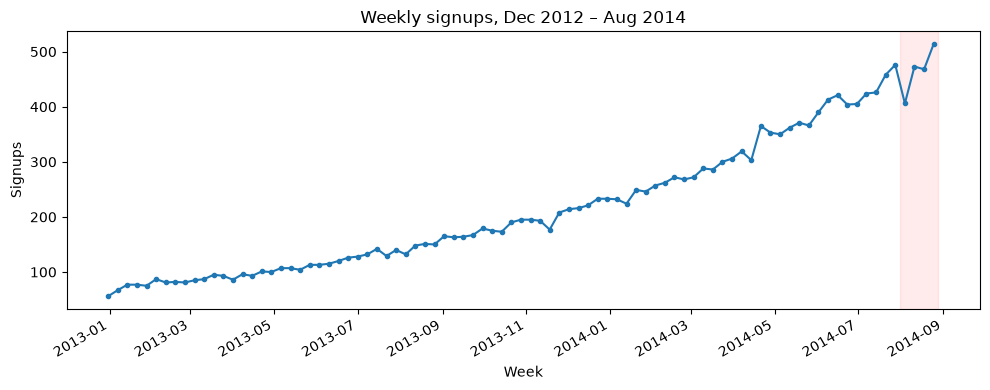

In [15]:
signups = pd.read_csv("../data/yammer_signups.csv", parse_dates=["week"])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(signups["week"], signups["signups"], marker="o", markersize=3)
mark_dip(ax)
ax.set_xlabel("Week"); ax.set_ylabel("Signups")
ax.set_title("Weekly signups, Dec 2012 – Aug 2014")
fig.autofmt_xdate(); fig.tight_layout()
plt.show()

**Verdict: decrease in signups ruled out.** Signups grew throughout the entire time period,
including during the dip weeks.

### Hypothesis: site/device-specific bug

**SQL (device categorization):**
```sql
-- sort devices by their type: desktop/laptop, phone, tablet, other (if any), then get events per device type
WITH categorized AS (
  SELECT occurred_at, user_id,
    CASE
      WHEN device IN ('acer aspire desktop','acer aspire notebook','asus chromebook',
        'dell inspiron desktop','dell inspiron notebook','hp pavilion desktop',
        'lenovo thinkpad','macbook air','macbook pro','mac mini','windows surface')
        THEN 'desktop/laptop'
      WHEN device IN ('amazon fire phone','htc one','iphone 4s','iphone 5','iphone 5s',
        'nexus 5','nokia lumia 635','samsung galaxy note','samsung galaxy s4')
        THEN 'phone'
      WHEN device IN ('ipad air','ipad mini','kindle fire','nexus 10','nexus 7',
        'samsumg galaxy tablet') --typo for samsung
        THEN 'tablet'
      ELSE 'other'
    END AS device_category
  FROM tutorial.yammer_events
  WHERE event_type = 'engagement'
)
SELECT DATE_TRUNC('week', occurred_at) AS week, device_category,
       COUNT(*) AS events, COUNT(DISTINCT user_id) AS distinct_users
FROM categorized
GROUP BY 1, 2
ORDER BY 2, 1
```

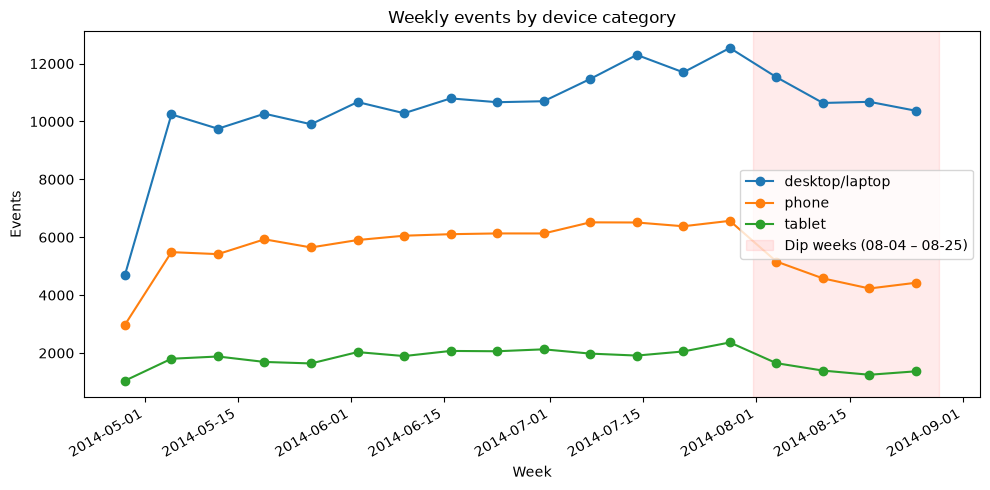

In [16]:
dc = pd.read_csv("../data/yammer_device_category.csv", parse_dates=["week"])
dc["events_per_user"] = dc["events"] / dc["distinct_users"]
dc = dc.sort_values(["device_category","week"]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5))
for cat in dc["device_category"].unique():
    sub = dc[dc["device_category"] == cat]
    ax.plot(sub["week"], sub["events"], marker="o", label=cat)
mark_dip(ax)
ax.set_xlabel("Week"); ax.set_ylabel("Events"); ax.legend()
ax.set_title("Weekly events by device category")
fig.autofmt_xdate(); fig.tight_layout()
plt.show()

The plot shows that desktop/laptop remains near baseline during the dip weeks, while phone/tablet drop significantly below their baseline. Let's examine this dip using the distinct users vs events per user analysis done in Step 2 (ie, find percent change for each, then take log of growth to determine relative contribution to drop).

In [17]:
cols = ["events", "distinct_users", "events_per_user"]
for c in cols:
    dc[f"prev_{c}"] = dc.groupby("device_category")[c].shift(1)

baseline = dc[dc["week"].isin(BASELINE_WEEKS)].groupby("device_category")[cols].mean()
dip = dc[dc["week"].isin(DIP_WEEKS)].groupby("device_category")[cols].mean()
pct_change = ((dip - baseline) / baseline * 100).round(1)
pct_change.columns = [f"pct_change_{c}" for c in cols]
print("Percent change, baseline (06-30 to 07-28) vs. dip (08-04 to 08-25):\n")
print(pct_change.to_string())

Percent change, baseline (06-30 to 07-28) vs. dip (08-04 to 08-25):

                 pct_change_events  pct_change_distinct_users  pct_change_events_per_user
device_category                                                                          
desktop/laptop                -8.0                       -1.1                        -7.0
phone                        -28.4                      -23.5                        -6.5
tablet                       -32.2                      -29.6                        -3.9


In [18]:
log_growth = pd.DataFrame({c: np.log(dc[c]/dc[f"prev_{c}"]) for c in cols}, index=dc.index)
log_growth["week"] = dc["week"]; log_growth["device_category"] = dc["device_category"]
dip_log = log_growth[log_growth["week"].isin(DIP_WEEKS)]
log_summary = dip_log.groupby("device_category")[cols].mean()

device_shares = pd.DataFrame(index=log_summary.index)
device_shares["share_users"] = (log_summary["distinct_users"] / log_summary["events"] * 100).round(1)
device_shares["share_per_user"] = (log_summary["events_per_user"] / log_summary["events"] * 100).round(1)
device_shares["pct_change_events"] = pct_change["pct_change_events"]
device_shares = device_shares.sort_values("pct_change_events")
print(device_shares.to_string())

                 share_users  share_per_user  pct_change_events
device_category                                                
tablet                  88.4            11.6              -32.2
phone                   73.4            26.6              -28.4
desktop/laptop          49.1            50.9               -8.0


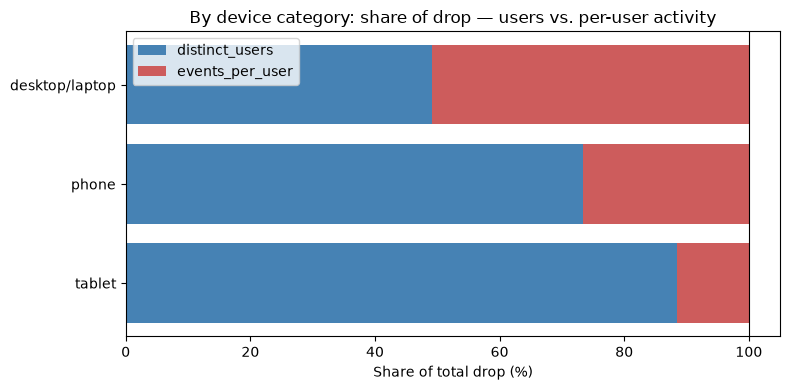

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
y_pos = range(len(device_shares))
ax.barh(y_pos, device_shares["share_users"], color="steelblue", label="distinct_users")
ax.barh(y_pos, device_shares["share_per_user"], left=device_shares["share_users"], color="indianred", label="events_per_user")
ax.set_yticks(list(y_pos)); ax.set_yticklabels(device_shares.index)
ax.axvline(100, color="black", linewidth=0.8)
ax.set_xlabel("Share of total drop (%)")
ax.set_title("By device category: share of drop — users vs. per-user activity")
ax.legend(); fig.tight_layout()
plt.show()

**Verdict: phone/tablet devices experience a significant drop, not ruled out.** No single device shows an
isolated drop (device-level pct changes are mixed, some even
positive). But at the *category* level, phone (-28.4%) and tablet (-32.2%)
dropped roughly 4x more than desktop/laptop (-8.0%). In addition, the *mechanism*
differs sharply: phone/tablet drops are dominated by a "fewer users" story
(people stopped showing up), while desktop's drop is an even split.
This suggests that something disrupted the mobile experience,
but check the cohort x device section below: the desktop figure in that section includes
new signups' activity, which offsets a larger decline among existing desktop
users, so the mobile-vs-desktop gap is smaller than it looks.

## Who stopped showing up? Engagement by fixed signup cohort

Users are bucketed by account age **as of one fixed reference date
(2014-06-30, the start of the baseline window)** and then followed through
baseline and dip. This holds the *same people* constant, unlike a rolling
"age at the time of each event" bucket, where people drift between buckets
and new signups keep refilling the youngest one. Only users who signed up
before 06-30 are included, so every member existed for the whole baseline.
Later signups are handled separately below.

**SQL:**
```sql
WITH cohorts AS (
  SELECT
    user_id,
    CASE
      WHEN ('2014-06-30'::date - created_at::date) < 30  THEN '0-1 month'
      WHEN ('2014-06-30'::date - created_at::date) < 90  THEN '1-3 months'
      WHEN ('2014-06-30'::date - created_at::date) < 180 THEN '3-6 months'
      WHEN ('2014-06-30'::date - created_at::date) < 365 THEN '6-12 months'
      ELSE '12+ months'
    END AS cohort
  FROM tutorial.yammer_users
  WHERE created_at < '2014-06-30'
),
cohort_sizes AS (
  SELECT cohort, COUNT(*) AS cohort_size FROM cohorts GROUP BY 1
)
SELECT
  DATE_TRUNC('week', e.occurred_at) AS week,
  c.cohort,
  s.cohort_size,
  COUNT(*) AS events,
  COUNT(DISTINCT e.user_id) AS distinct_users
FROM tutorial.yammer_events e
JOIN cohorts c ON e.user_id = c.user_id
JOIN cohort_sizes s ON c.cohort = s.cohort
WHERE e.event_type = 'engagement'
GROUP BY 1, 2, 3
ORDER BY 2, 1
```

In [20]:
cohorts = pd.read_csv("../data/yammer_cohorts.csv", parse_dates=["week"])
COHORT_ORDER = ["0-1 month", "1-3 months", "3-6 months", "6-12 months", "12+ months"]
cohorts["events_per_user"] = cohorts["events"] / cohorts["distinct_users"]
cohorts["active_rate_%"] = cohorts["distinct_users"] / cohorts["cohort_size"] * 100

cols = ["events", "distinct_users", "events_per_user", "active_rate_%"]
c_base = cohorts[cohorts["week"].isin(BASELINE_WEEKS)].groupby("cohort")[cols].mean()
c_dip = cohorts[cohorts["week"].isin(DIP_WEEKS)].groupby("cohort")[cols].mean()
c_pct = ((c_dip - c_base) / c_base * 100).round(1).loc[COHORT_ORDER]
c_pct = c_pct[["events", "distinct_users", "events_per_user"]]
c_pct.columns = ["pct_change_events", "pct_change_distinct_users", "pct_change_events_per_user"]
print("Baseline (06-30 to 07-28) vs. dip (08-04 to 08-25), % change:")
print(c_pct.to_string())
print()
print("Weekly active rate (% of cohort active in a week), baseline -> dip:")
print(pd.DataFrame({"baseline": c_base["active_rate_%"], "dip": c_dip["active_rate_%"]})
      .loc[COHORT_ORDER].round(2).to_string())

Baseline (06-30 to 07-28) vs. dip (08-04 to 08-25), % change:
             pct_change_events  pct_change_distinct_users  pct_change_events_per_user
cohort                                                                               
0-1 month                -71.2                      -67.7                       -10.9
1-3 months               -41.1                      -35.2                        -9.0
3-6 months               -19.8                      -20.6                         0.0
6-12 months              -28.7                      -28.5                        -0.1
12+ months               -38.1                      -35.1                        -4.4

Weekly active rate (% of cohort active in a week), baseline -> dip:
             baseline   dip
cohort                     
0-1 month       12.32  3.98
1-3 months       5.58  3.61
3-6 months       5.43  4.31
6-12 months      5.01  3.58
12+ months       6.01  3.90


These level changes include **natural cohort decay**: new users are most
active right after signing up and then taper off. So a level comparison alone
can't tell decay from the dip. The next cell checks for a **break**: did each
cohort's week-over-week trend change when the dip began?

In [21]:
users = cohorts.pivot(index="week", columns="cohort", values="distinct_users")
events = cohorts.pivot(index="week", columns="cohort", values="events")
pre_weeks = pd.to_datetime(["2014-07-07", "2014-07-14", "2014-07-21", "2014-07-28"])  # changes into these weeks

def avg_wow(table, weeks):
    return (table.pct_change() * 100).loc[weeks].mean()

break_test = pd.DataFrame({
    "users_wow_pre_%": avg_wow(users, pre_weeks),
    "users_wow_dip_%": avg_wow(users, DIP_WEEKS),
    "events_wow_pre_%": avg_wow(events, pre_weeks),
    "events_wow_dip_%": avg_wow(events, DIP_WEEKS),
}).loc[COHORT_ORDER].round(1)
print("Average week-over-week % change, 4 pre-dip weeks vs. 4 dip weeks:")
print(break_test.to_string())

# Combined effect on the three cohorts older than 3 months (cohorts are disjoint, so user counts can be summed)
older = cohorts[cohorts["cohort"].isin(["3-6 months", "6-12 months", "12+ months"])].groupby("week")[["events", "distinct_users"]].sum()
older_base = older.loc[BASELINE_WEEKS].mean(); older_dip = older.loc[DIP_WEEKS].mean()
print()
print("Cohorts older than 3 months, combined, baseline -> dip % change:")
print(((older_dip - older_base) / older_base * 100).round(1).to_string())

Average week-over-week % change, 4 pre-dip weeks vs. 4 dip weeks:
             users_wow_pre_%  users_wow_dip_%  events_wow_pre_%  events_wow_dip_%
cohort                                                                           
0-1 month              -24.3            -21.0             -25.7             -20.9
1-3 months               2.5            -16.2              -0.7             -15.3
3-6 months              -0.9             -7.7               0.6              -5.4
6-12 months             -1.7            -10.7              -2.9             -11.0
12+ months               2.6            -10.3               6.4             -13.6

Cohorts older than 3 months, combined, baseline -> dip % change:
events           -28.9
distinct_users   -27.6


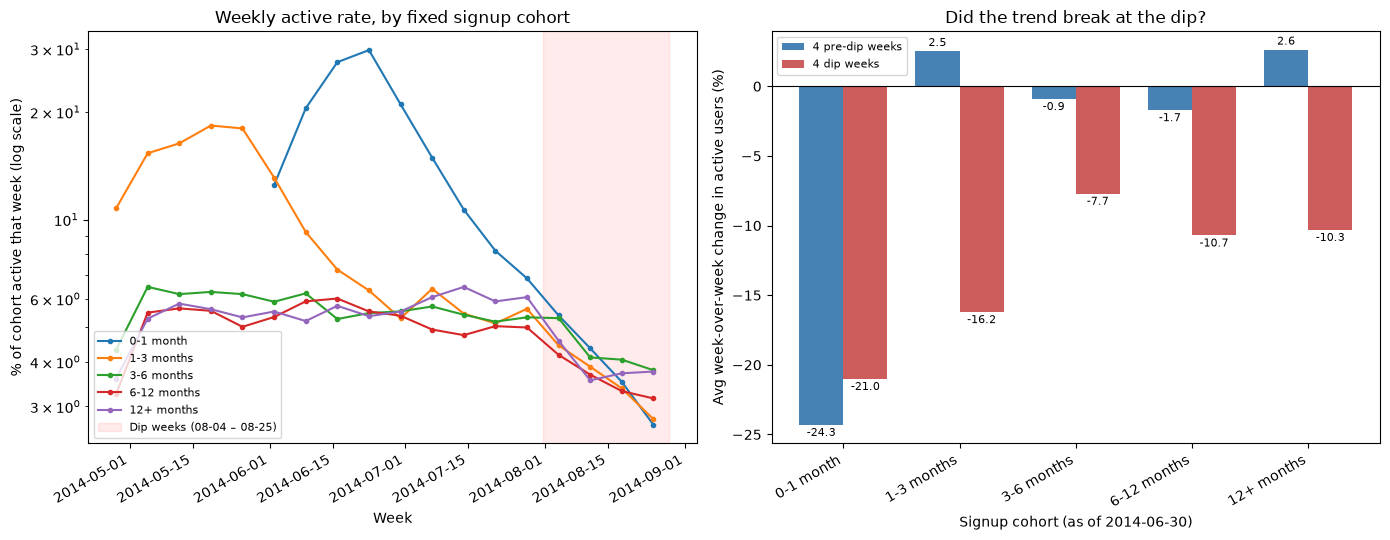

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

for cohort in COHORT_ORDER:
    sub = cohorts[(cohorts["cohort"] == cohort) & (cohorts["events"] > 100)]  # skip the partial first week
    ax1.plot(sub["week"], sub["active_rate_%"], marker="o", markersize=3, label=cohort)
mark_dip(ax1)
ax1.set_yscale("log")
ax1.set_xlabel("Week"); ax1.set_ylabel("% of cohort active that week (log scale)")
ax1.set_title("Weekly active rate, by fixed signup cohort")
ax1.legend(fontsize=8, loc="lower left")

x = np.arange(len(COHORT_ORDER)); w = 0.38
for k, (col, label, color) in enumerate([("users_wow_pre_%", "4 pre-dip weeks", "steelblue"),
                                         ("users_wow_dip_%", "4 dip weeks", "indianred")]):
    bars = ax2.bar(x + (k - 0.5) * w, break_test[col], w, color=color, label=label)
    ax2.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_xticks(x); ax2.set_xticklabels(COHORT_ORDER)
ax2.set_xlabel("Signup cohort (as of 2014-06-30)")
ax2.set_ylabel("Avg week-over-week change in active users (%)")
ax2.set_title("Did the trend break at the dip?")
ax2.legend(fontsize=8)
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig("../figures/cohort_analysis.png", dpi=150, bbox_inches="tight")  # for the README
plt.show()

### New signups offset part of the decline

Users who signed up **after** 06-30 aren't in any fixed cohort. Their events
are whatever is left after subtracting the cohorts from platform totals:

In [23]:
total_events = dc.groupby("week")["events"].sum()          # platform total, from the device-category export
cohort_events = cohorts.groupby("week")["events"].sum()    # all five fixed cohorts
newer = total_events - cohort_events                       # users who signed up after 06-30

# Sanity check: before 06-30 every user belongs to a fixed cohort, so the remainder must be 0.
assert (newer.loc[newer.index < "2014-06-30"] == 0).all()

pd.DataFrame({
    "platform_events": total_events,
    "fixed_cohorts": cohort_events,
    "signed_up_after_06-30": newer,
    "share_from_newer_%": (newer / total_events * 100).round(1),
}).loc["2014-06-30":]

,platform_events,fixed_cohorts,signed_up_after_06-30,share_from_newer_%
week,,,,
2014-06-30,18959,16659,2300,12.1
2014-07-07,19965,15296,4669,23.4
2014-07-14,20723,14786,5937,28.6
2014-07-21,20132,13603,6529,32.4
2014-07-28,21472,13060,8412,39.2
2014-08-04,18341,11021,7320,39.9
2014-08-11,16612,8736,7876,47.4
2014-08-18,16158,8355,7803,48.3
2014-08-25,16166,7499,8667,53.6


**Verdict.**

- **Every cohort that was already past its first month on 06-30 shows a clear
  break at the dip.** Before it, their active users were roughly flat. During the dip, their events fell about 8–16%
  per week (3–6 months: -7.7%, 6–12 months: -10.7%, 12+ months: -10.3%,
  1–3 months: -16%). For the cohorts older than 3 months, the drop is almost
  entirely fewer active users; events per user changed by only 0 to -4.4%.
  Combined, those three cohorts lost about **29% of their weekly events and
  28% of their active users**.
- **The newest cohort (0–1 month on 06-30) doesn't follow the same pattern.** Its
  active users were already falling ~24% per week before the dip
   and kept falling at a similar rate (-21%) during it. This could be attributed to natural decay after signing up. There
  is no visible break in events, so the dip can't be separated from natural decay for
  this group.
- **New signups masked part of the decline.** Events from users who signed up
  after 06-30 grew from about 2,300 per week on 06-30 to about 8,400 by 07-28, then held
  steady at roughly 8,000 per week through the dip (54% of platform
  events by 08-25). Over the same weeks, the fixed cohorts' weekly events fell
  about 40% (baseline vs. dip), while the platform total fell only 16.9%.

**Caveats:** cohort size counts everyone who signed up, including accounts that
never became active, so active rates are low and best used for comparison
across time rather than as absolute figures. Whether these cohorts overlap
with the mobile users from the device analysis (a `cohort x device` cut) is
tested below.

## Is the existing-user drop the same population as the mobile drop?

The device and cohort analyses were done separately to examine the same drop. If
mobile users skew toward the cohorts that dropped (or the reverse), each
finding could partly be an artifact of the other. Therefore, we should check 
each cohorts by device type to examine the drop more carefully.
Cohorts will be bucketed into three groups and devices into two to keep each cell
large enough to read.

**SQL:**
```sql
WITH cohorts AS (
  SELECT
    user_id,
    CASE
      WHEN ('2014-06-30'::date - created_at::date) < 30 THEN '0-1 month'
      WHEN ('2014-06-30'::date - created_at::date) < 90 THEN '1-3 months'
      ELSE '3+ months'
    END AS cohort
  FROM tutorial.yammer_users
  WHERE created_at < '2014-06-30'
)
SELECT
  DATE_TRUNC('week', e.occurred_at) AS week,
  c.cohort,
  CASE
    WHEN e.device IN ('amazon fire phone','htc one','iphone 4s','iphone 5','iphone 5s',
                      'nexus 5','nokia lumia 635','samsung galaxy note','samsung galaxy s4',
                      'ipad air','ipad mini','kindle fire','nexus 10','nexus 7',
                      'samsumg galaxy tablet') THEN 'mobile'
    ELSE 'desktop/laptop'
  END AS device_group,
  COUNT(*) AS events,
  COUNT(DISTINCT e.user_id) AS distinct_users
FROM tutorial.yammer_events e
JOIN cohorts c ON e.user_id = c.user_id
WHERE e.event_type = 'engagement'
GROUP BY 1, 2, 3
ORDER BY 2, 3, 1
```
A user active on both device types is counted in both groups, so the groups
don't sum to the cohort total. This should not affect comparing trends within each
group.

In [28]:
cd_dev = pd.read_csv("../data/yammer_cohort_device.csv", parse_dates=["week"])
cd_dev["events_per_user"] = cd_dev["events"] / cd_dev["distinct_users"]
keys = ["cohort", "device_group"]
GROUP_ORDER = [("0-1 month", "desktop/laptop"), ("0-1 month", "mobile"),
               ("1-3 months", "desktop/laptop"), ("1-3 months", "mobile"),
               ("3+ months", "desktop/laptop"), ("3+ months", "mobile")]

cols = ["events", "distinct_users", "events_per_user"]
cb = cd_dev[cd_dev["week"].isin(BASELINE_WEEKS)].groupby(keys)[cols].mean()
cdp = cd_dev[cd_dev["week"].isin(DIP_WEEKS)].groupby(keys)[cols].mean()
level = ((cdp - cb) / cb * 100).round(1).loc[GROUP_ORDER]
level.columns = ["pct_change_events", "pct_change_distinct_users", "pct_change_events_per_user"]
print("Baseline (06-30 to 07-28) vs. dip (08-04 to 08-25), % change:")
print(level.to_string())

u = cd_dev.pivot_table(index="week", columns=keys, values="distinct_users")
trend = pd.DataFrame({
    "users_wow_pre_%": (u.pct_change() * 100).loc[pre_weeks].mean(),
    "users_wow_dip_%": (u.pct_change() * 100).loc[DIP_WEEKS].mean(),
}).loc[GROUP_ORDER]
trend["change_in_trend_pts"] = trend["users_wow_dip_%"] - trend["users_wow_pre_%"]
print()
print("Average week-over-week % change in active users, 4 pre-dip weeks vs. 4 dip weeks:")
print(trend.round(1).to_string())
print()
print("Weekly active users per group (min-max over the 9 baseline and dip weeks):")
print(u.loc[BASELINE_WEEKS.append(DIP_WEEKS)].agg(["min", "max"]).T.loc[GROUP_ORDER].to_string())

Baseline (06-30 to 07-28) vs. dip (08-04 to 08-25), % change:
                           pct_change_events  pct_change_distinct_users  pct_change_events_per_user
cohort     device_group                                                                            
0-1 month  desktop/laptop              -66.9                      -62.9                        -8.5
           mobile                      -76.9                      -76.1                        -4.5
1-3 months desktop/laptop              -28.9                      -23.3                        -7.7
           mobile                      -56.7                      -54.0                        -6.6
3+ months  desktop/laptop              -17.7                      -16.9                        -1.0
           mobile                      -45.5                      -41.4                        -7.4

Average week-over-week % change in active users, 4 pre-dip weeks vs. 4 dip weeks:
                           users_wow_pre_%  users_wow_d

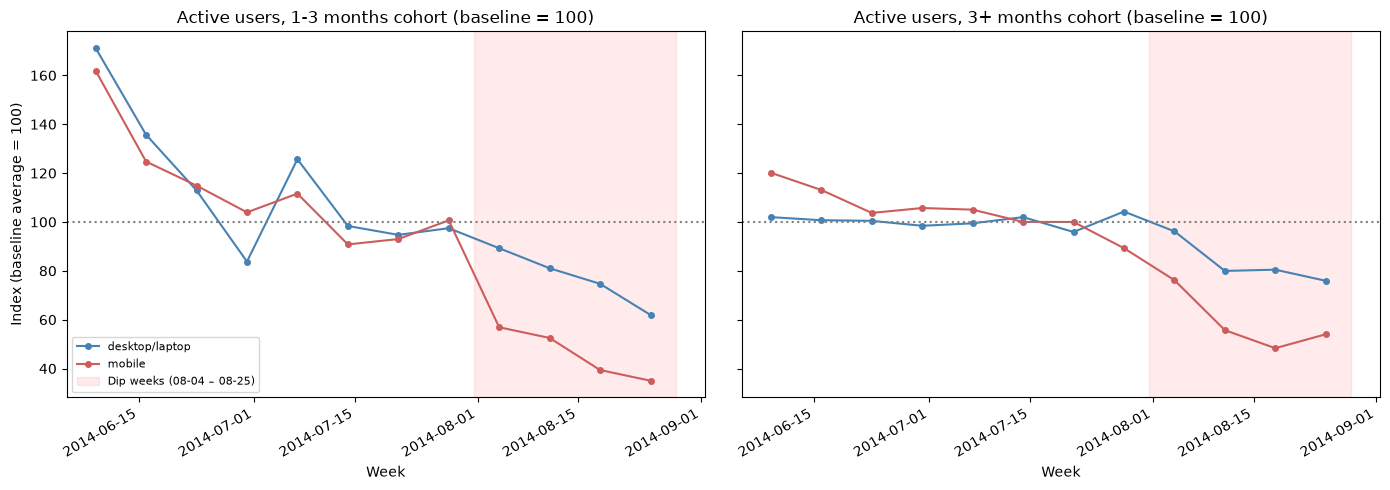

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, cohort in zip(axes, ["1-3 months", "3+ months"]):
    for dev, color in [("desktop/laptop", "steelblue"), ("mobile", "indianred")]:
        series = u[(cohort, dev)].loc["2014-06-09":]
        ax.plot(series.index, series / u[(cohort, dev)].loc[BASELINE_WEEKS].mean() * 100,
                marker="o", markersize=4, color=color, label=dev)
    mark_dip(ax, label=(cohort == "1-3 months"))
    ax.axhline(100, color="gray", linestyle=":")
    ax.set_title(f"Active users, {cohort} cohort (baseline = 100)")
    ax.set_xlabel("Week")
axes[0].set_ylabel("Index (baseline average = 100)")
axes[0].legend(fontsize=8)
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig("../figures/cohort_by_device.png", dpi=150, bbox_inches="tight")  # for the README
plt.show()

The platform-level device split earlier showed desktop falling far less than
mobile. Part of that is new signups' activity offsetting the decline. Splitting
platform events into existing users (signed up before 06-30) and the rest:

In [27]:
dc_dev = dc.assign(group=np.where(dc["device_category"] == "desktop/laptop", "desktop/laptop", "mobile"))
platform_dev = dc_dev.groupby(["week", "group"])["events"].sum().unstack()
existing_dev = cd_dev.groupby(["week", "device_group"])["events"].sum().unstack()
newer_dev = platform_dev - existing_dev          # users who signed up after 06-30

# Sanity check: before 06-30 everyone is in a fixed cohort, so the remainder must be 0.
assert (newer_dev.loc[newer_dev.index < "2014-06-30"] == 0).all().all()

def level_change(table):
    b_, d_ = table.loc[BASELINE_WEEKS].mean(), table.loc[DIP_WEEKS].mean()
    return ((d_ - b_) / b_ * 100).round(1)

mobile_share_existing = existing_dev.loc[BASELINE_WEEKS, "mobile"].sum() / existing_dev.loc[BASELINE_WEEKS].sum().sum() * 100
mobile_share_newer = newer_dev.loc["2014-07-07":, "mobile"].sum() / newer_dev.loc["2014-07-07":].sum().sum() * 100
print(f"Mobile share of events: existing users at baseline {mobile_share_existing:.1f}%, newer users {mobile_share_newer:.1f}%")

pd.DataFrame({
    "platform": level_change(platform_dev),
    "existing users (signed up before 06-30)": level_change(existing_dev),
})

Mobile share of events: existing users at baseline 41.6%, newer users 41.5%


,platform,existing users (signed up before 06-30)
desktop/laptop,-8.0,-28.9
mobile,-29.3,-54.0


**Verdict: the existing-user drop is not mobile-only, and the earlier device
comparison understated desktop.**

- **Established users decreased significantly for both device types.** For users older than 3
  months on 06-30, weekly active users on desktop/laptop went from +1.6% per
  week before the dip to -7.4% during it; on mobile from -4.0% to -10.7%. For
  the 1-3 month group: desktop +6.9% to -10.6%, mobile -0.2% to -21.8%.
- **Mobile fell further and faster at the onset, but part of the
  level gap predates the dip.** For the 3+ month group, active users fell 41%
  on mobile vs. 17% on desktop. But mobile was already decreasing before the dip
  (about -16% from 06-30 to 07-28) while desktop was flat to rising (+6%). The
  average *change in trend* is comparable on both devices for 3+ months (-6.7
  points per week on mobile, -9.0 on desktop; the mobile average is pulled up
  by a positive rebound in the last week) and larger on mobile for 1-3 months
  (-21.7 vs. -17.5). The shape differs, though: mobile dropped sharply in the
  first dip weeks while desktop declined more gradually. The 1-3 month group has only about 30-140 users per
  week per device, so treat it as noisy.
- **The platform-level desktop figure was masked by new signups.** Platform
  desktop events fell 8%, but among existing users they fell 29% (mobile:
  54%). New signups have a similar device mix to existing users (about 41%
  mobile), so this is simply their activity offsetting the decline.

Mobile consistently had the largest decreases, so it remains the most affected group, but
"something broke only on mobile" is not the full story. The data fit either a
mobile-specific failure on top of a broader problem, or one broad disruption
that mobile users were more exposed to. The email
clickthrough collapse supports either possibility. The 0-1 month cohort is
dominated by natural decay and is not interpreted here.

## Conclusion

The engagement drop starting 2014-08-04 is real, sustained, and driven
primarily by **fewer distinct users** rather than lower per-user activity.
It is concentrated among **existing users**: every signup cohort older than
one month shows a clear break at the dip, on both mobile and desktop, while
newer signups kept arriving and engaging. The newest cohort's own trajectory 
is dominated by natural decay, so it can't be assessed.

- **Mobile (phone and tablet) users took the largest hit**, stronger and
sharper at the onset, though already sliding before the dip, but the
cohort-by-device analysis shows the break is not mobile-only: established desktop
users decreased as well. The given data can't distinguish a
mobile-specific failure plus a broader problem from one broad disruption that
mobile users were more exposed to.

A second signal is consistent with either: email clickthrough *rate* collapsed
~32% the same week, with opens unaffected. The drop is spread across
countries and regions, not concentrated in any one. Holiday/location, signup
decline, and email *delivery* were ruled out. **The most actionable next step would be
investigating what changed in the product (the mobile app, notification links,
and shared backend) around the week of 2014-08-04.**